Set up

In [1]:
import pandas as pd
import numpy as np
import json
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.metrics import (precision_recall_curve, roc_curve,
                             confusion_matrix, classification_report)

PROCESSED = Path("../processed")
FIGURES   = Path("../figures")

# Load predictions and ground truth
y_pred_proba = np.load(PROCESSED / "y_pred_proba_test.npy")
y_test       = np.load(PROCESSED / "y_test.npy")

with open(PROCESSED / "metrics_base.json", "r") as f:
    metrics_base = json.load(f)

print(f"Test samples: {len(y_test)}")
print(f"Fraud rate in test: {y_test.mean():.4f}")
print(f"Base metrics: {metrics_base}")

Test samples: 88581
Fraud rate in test: 0.0349
Base metrics: {'roc_auc': 0.9103, 'pr_auc': 0.5303, 'threshold_default': 0.5, 'n_features': 74}


Define business costs

In [2]:
# Business cost assumptions
# FN: missed fraud = full transaction amount lost
# FP: false alert = cost of manual review by fraud analyst

AVG_TRANSACTION_AMT = 135.0   # mean TransactionAmt from EDA
FN_COST = AVG_TRANSACTION_AMT  # cost of missing a fraud
FP_COST = 10.0                 # cost of manual review (analyst time ~$10)

print("Business cost assumptions:")
print(f"  False Negative (missed fraud):    ${FN_COST:.2f} per transaction")
print(f"  False Positive (false alert):     ${FP_COST:.2f} per transaction")
print(f"  Cost ratio FN/FP: {FN_COST/FP_COST:.1f}x")

Business cost assumptions:
  False Negative (missed fraud):    $135.00 per transaction
  False Positive (false alert):     $10.00 per transaction
  Cost ratio FN/FP: 13.5x


Profit Curve

Optimal threshold: 0.13
Max profit: $134,120
Default threshold (0.5) profit: $-20,200
Profit improvement: $154,320


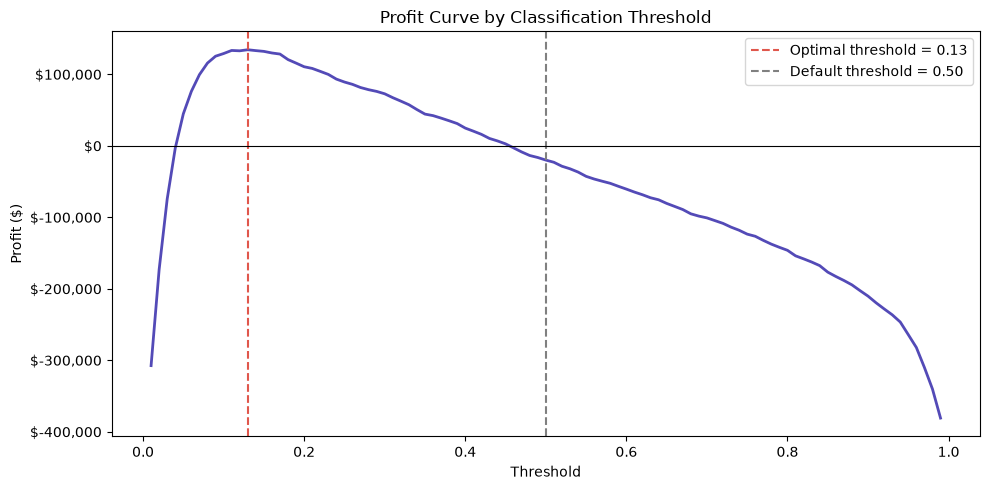

In [3]:
thresholds = np.arange(0.01, 1.0, 0.01)
profits = []

for threshold in thresholds:
    y_pred = (y_pred_proba >= threshold).astype(int)
    
    tn = ((y_pred == 0) & (y_test == 0)).sum()
    fp = ((y_pred == 1) & (y_test == 0)).sum()
    fn = ((y_pred == 0) & (y_test == 1)).sum()
    tp = ((y_pred == 1) & (y_test == 1)).sum()
    
    # Profit = fraud caught - cost of false alerts - cost of missed fraud
    profit = (tp * FN_COST) - (fp * FP_COST) - (fn * FN_COST)
    profits.append(profit)

profits = np.array(profits)
optimal_idx = profits.argmax()
optimal_threshold = thresholds[optimal_idx]
optimal_profit = profits[optimal_idx]

print(f"Optimal threshold: {optimal_threshold:.2f}")
print(f"Max profit: ${optimal_profit:,.0f}")
print(f"Default threshold (0.5) profit: ${profits[49]:,.0f}")
print(f"Profit improvement: ${optimal_profit - profits[49]:,.0f}")

# Plot
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(thresholds, profits, color="#534AB7", linewidth=2)
ax.axvline(optimal_threshold, color="#E0574C", linestyle="--", 
           label=f"Optimal threshold = {optimal_threshold:.2f}")
ax.axvline(0.5, color="gray", linestyle="--", 
           label="Default threshold = 0.50")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Threshold")
ax.set_ylabel("Profit ($)")
ax.set_title("Profit Curve by Classification Threshold")
ax.legend()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x:,.0f}"))
plt.tight_layout()
plt.savefig(FIGURES / "10_profit_curve.png", dpi=150)
plt.show()

In [4]:
for name, threshold in [("Default (0.5)", 0.5), 
                         (f"Optimal ({optimal_threshold:.2f})", optimal_threshold)]:
    y_pred = (y_pred_proba >= threshold).astype(int)
    tn = ((y_pred == 0) & (y_test == 0)).sum()
    fp = ((y_pred == 1) & (y_test == 0)).sum()
    fn = ((y_pred == 0) & (y_test == 1)).sum()
    tp = ((y_pred == 1) & (y_test == 1)).sum()
    
    recall    = tp / (tp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    profit    = (tp * FN_COST) - (fp * FP_COST) - (fn * FN_COST)
    
    print(f"\n--- {name} ---")
    print(f"  Fraud detected (TP):      {tp:,}  ({recall*100:.1f}% recall)")
    print(f"  Fraud missed (FN):        {fn:,}")
    print(f"  False alerts (FP):        {fp:,}")
    print(f"  Precision:                {precision:.3f}")
    print(f"  Revenue protected:        ${tp * FN_COST:,.0f}")
    print(f"  Cost of false alerts:     ${fp * FP_COST:,.0f}")
    print(f"  Cost of missed fraud:     ${fn * FN_COST:,.0f}")
    print(f"  Net profit:               ${profit:,.0f}")


--- Default (0.5) ---
  Fraud detected (TP):      1,516  (49.1% recall)
  Fraud missed (FN):        1,572
  False alerts (FP):        1,264
  Precision:                0.545
  Revenue protected:        $204,660
  Cost of false alerts:     $12,640
  Cost of missed fraud:     $212,220
  Net profit:               $-20,200

--- Optimal (0.13) ---
  Fraud detected (TP):      2,469  (80.0% recall)
  Fraud missed (FN):        619
  False alerts (FP):        11,563
  Precision:                0.176
  Revenue protected:        $333,315
  Cost of false alerts:     $115,630
  Cost of missed fraud:     $83,565
  Net profit:               $134,120


In [6]:
optimal_config = {
    "optimal_threshold": round(float(optimal_threshold), 2),
    "fn_cost": FN_COST,
    "fp_cost": FP_COST,
    "max_profit": round(float(optimal_profit), 2),
    "default_profit": round(float(profits[49]), 2),
    "profit_improvement": round(float(optimal_profit - profits[49]), 2)
}

with open(PROCESSED / "optimal_threshold.json", "w") as f:
    json.dump(optimal_config, f, indent=2)

print("Saved: optimal_threshold.json")
print(optimal_config)

Saved: optimal_threshold.json
{'optimal_threshold': 0.13, 'fn_cost': 135.0, 'fp_cost': 10.0, 'max_profit': 134120.0, 'default_profit': -20200.0, 'profit_improvement': 154320.0}


In [8]:
# Summary table for README
impact = {
    "Metric": [
        "Threshold",
        "Fraud detected (Recall)",
        "False alerts (FP)",
        "Precision",
        "Revenue protected",
        "Cost of false alerts",
        "Cost of missed fraud",
        "Net profit"
    ],
    "Default (0.50)": [
        "0.50",
        "49.1% (1,516 cases)",
        "1,264",
        "54.5%",
        "$204,660",
        "$12,640",
        "$212,220",
        "-$20,200"
    ],
    "Optimized (0.13)": [
        "0.13",
        "80.0% (2,469 cases)",
        "11,563",
        "17.6%",
        "$333,315",
        "$115,630",
        "$83,565",
        "+$134,120"
    ]
}

report = pd.DataFrame(impact).set_index("Metric")
print(report.to_string())

report.to_csv(PROCESSED / "business_impact_report.csv")
print("\nSaved: business_impact_report.csv")

                              Default (0.50)     Optimized (0.13)
Metric                                                           
Threshold                               0.50                 0.13
Fraud detected (Recall)  49.1% (1,516 cases)  80.0% (2,469 cases)
False alerts (FP)                      1,264               11,563
Precision                              54.5%                17.6%
Revenue protected                   $204,660             $333,315
Cost of false alerts                 $12,640             $115,630
Cost of missed fraud                $212,220              $83,565
Net profit                          -$20,200            +$134,120

Saved: business_impact_report.csv


## Summary

- Replaced the default threshold (0.5) with a business-optimal threshold 
  derived from a profit curve using explicit cost assumptions:
  - **False Negative cost**: $135 (average transaction amount lost to fraud)
  - **False Positive cost**: $10 (analyst manual review cost)
  - Cost ratio FN/FP = 13.5x

- **Optimal threshold: 0.13**

| Metric | Default (0.50) | Optimized (0.13) |
|--------|---------------|-----------------|
| Recall (Fraud) | 49.1% | 80.0% |
| False alerts | 1,264 | 11,563 |
| Revenue protected | $204,660 | $333,315 |
| Net profit | -$20,200 | +$134,120 |

- **Key insight**: at threshold=0.5 the model loses $20,200 — the cost of 
  missed fraud exceeds the value it generates. Lowering the threshold to 
  0.13 produces a net profit of $134,120 — a $154,320 improvement.
- Threshold 0.13 is operationally reasonable: detects 80% of fraud with 
  a manageable false alert rate.

**Outputs:** `optimal_threshold.json`, `business_impact_report.csv`, 
`figures/10_profit_curve.png`